# 4.9. Boundary Elements for Plane Elastodynamics using space quadratic elements (QUADPLET)

A FORTRAN code that uses (QUA)dratic elements for the solution of (D)ynamic (PL)ane (E)lastic time-(D)omain problems is described next.

The structure of the program is very similar to that of the harmonic ones (Figure 2.8), the major difference being the new block called PREST (PREvious STeps). This subroutine computes the known vector $F^n$ in equation (4.65), adding the contribution of previous steps and the current one. The subroutine INTER for computation of variables at internal points, has been omitted but it could be readily implemented without difficulty.

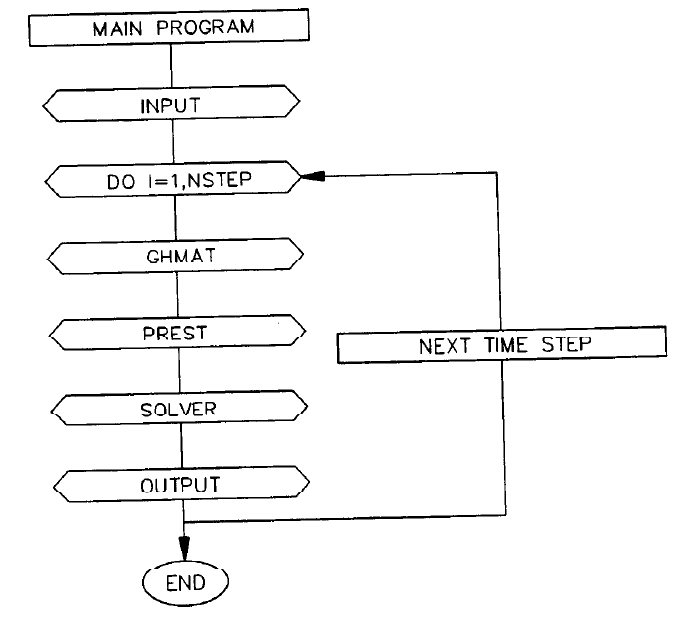

# Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
ls

drive/  sample_data/


# Copy files from Drive to Colab

In [3]:
cp /content/drive/MyDrive/"Colab Notebooks"/BEM/Codigos_Livros/dominguez/* .

In [4]:
ls

 bessel                          fundsole     output1
 cdot                            fundsols     output10
 condapeh                        funtheh      output11
 condapeh.for                    ghmat1       output12
 condapeh.ilk                    ghmat10      output13
 condapeh.mdp                    ghmat11      output14
 condpleh.for                    ghmat12      output2
 condpleh.ilk                    ghmat13      output3
 condpleh.mdp                    ghmat14      output4
 condplet                        ghmat2       output5
 condplet.for                    ghmat3       output6
 condplst                        ghmat4       output7
 condplst.for                    ghmat5       output8
 condplst.ilk                    ghmat6       output9
 condplst.mdp                    ghmat7       output.dat
 condpoeh                        ghmat8       prest10
 condpoeh.for                    ghmat9       prest11
 condpoeh.ilk                    heat10.dat   prest12
 condpoeh.mdp       

# Install meshio

In [5]:
!pip install meshio[all]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.2/166.2 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 56.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 42.1 MB/s eta 0:00:00


# Install Gmsh

In [6]:
!apt-get update
!apt-get install gmsh
!python -m pip install gmsh

Get:1 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:2 https://cli.github.com/packages stable InRelease
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:7 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,052 kB]
Get:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:9 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,545 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,373 kB]
Get:12 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,021 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.3 MB]


# Gmsh geometry file (```.geo```)

In [27]:
%%writefile placa.geo
ref=1.;
L=2.;
H = 4.;
Point(1) = {0, 0, 0, ref};
Point(2) = {L, 0, 0, ref};
Point(3) = {L, H, 0, ref};
Point(4) = {0, H, 0, ref};
Line(1) = {1, 2};
Line(2) = {2, 3};
Line(3) = {3, 4};
Line(4) = {4, 1};
Line Loop(1) = {1, 2, 3, 4};
Plane Surface(1) = {1};
Physical Curve("botton") = {1};
Physical Curve("right") = {2};
Physical Curve("top") = {3};
Physical Curve("left") = {4};
Physical Surface("surf1") = {1};

Overwriting placa.geo


# Generate mesh file (```.msh```) using Gmsh

In [46]:
!gmsh -1  placa.geo -o placa.msh  -order 2

Info    : Running '/usr/local/bin/gmsh -1 placa.geo -o placa.msh -order 2' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Thu Oct  8 18:41:03 2026
Info    : Reading 'placa.geo'...
Info    : Done reading 'placa.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000557563s, CPU 0.000494s)
Info    : Meshing order 2 (curvilinear on)...
Info    : [  0%] Meshing curve 1 order 2
Info    : [ 30%] Meshing curve 2 order 2
Info    : [ 50%] Meshing curve 3 order 2
Info    : [ 70%] Meshing curve 4 order 2
Info    : [ 90%] Meshing surface 1 order 2
Info    : Done meshing order 2 (Wall 0.000241505s, CPU 0.000229s)
Info    : 24 nodes 16 elements
Info    : Writing 'placa.msh'...
Info    : Done writing 'placa.msh'
Info    : Stopped on Thu Oct  8 18:41:03 2026 (From start: Wall 0.00459682s, CPU 0.234383s)


# Generate input data for the Fortran analysis

In [85]:
import numpy as np
import meshio

def input_data():
    """
    This function defines input parameters for the Boundary Element Method (BEM)
    simulation applied to the plane elasticity equation with radial integration for domain
    integrals.

    Returns:
        dict: A dictionary containing the following key-value pairs:
            * bound_cond (dict): Boundary conditions for each edge:
                *
            * E (float): Material elastic modulus
            * nu (float): Poisson's ratio
            * file_name (str): Name of the .msh file (Gmsh mesh)
            * qpoint (str): String representing the coordinates of the heat source point
    """
    # Directly define values here for scripting (modify as needed)
    # Boundary conditions are specified in local coordinate system (normal-tangent)
    # type_x = type of the boundary condition in x direction
    # type_y = type of the boundary condition in y direction
    #    (type_x and type_y: 0 = displacement is know while 1 = traction is known)

    bound_cond = {'botton': {'type_x': 1, 'value_x': 0., 'tfun': 1, 'type_y': 0, 'value_y': 0., 'tfun': 1},
                  'right': {'type_x': 0, 'value_x': 0., 'tfun': 1, 'type_y': 1, 'value_y': 0., 'tfun': 1},
        'top': {'type_x': 1, 'value_x': 0., 'tfun': 1, 'type_y': 1, 'value_y': 25., 'tfun': 1},
        'left': {'type_x': 0, 'value_x': 0., 'tfun': 1, 'type_y': 1, 'value_y': 0., 'tfun': 1}
    }

    E = 260.0e8 # # Elastic modulus
    nu = 0.3 # Poisson ration
    file_name = 'placa'
    rho = 5000. # density
    tstep = 2.0E-4 # time step
    ntfunctions = 1 # number of time functions

    return {'bound_cond': bound_cond, 'E': E, 'nu': nu, 'file_name': file_name,\
            'rho' : rho, 'tstep' : tstep, 'ntfunctions' : ntfunctions}

In [86]:
# Read information about input data
inp_data = input_data()

In [87]:
def compute_inodes(file_name, bound_cond):
    """
    This function reads a mesh file and extracts information about nodes, elements,
    and boundary conditions.

    Args:
      file_name: Name of the mesh file.
      bound_cond: Dictionary containing boundary conditions for each edge.

    Returns:
      A dictionary containing information about nodes, elements, and boundary
      conditions.
    """
    mesh = meshio.read(file_name + '.msh')
    coordinates = mesh.points
    line_elements = mesh.cells_dict['line3']
    segments = mesh.cell_data_dict['gmsh:physical']['line3']

    bc_info = {}
    for key, value in bound_cond.items():
        segment = mesh.field_data[key][0]
        bc_info[key] = {
            'type_x': value['type_x'],
            'value_x': value['value_x'],
            'segment': segment,
            'type_y': value['type_y'],
            'value_y': value['value_y']
        }

    boundary_nodes = np.unique(line_elements)

    return {
        'nodes': boundary_nodes,
        'coordinates': coordinates,
        'elements': line_elements,
        'segments': segments,
        'bc_info': bc_info
    }

In [88]:
# Format input data
computed_data = compute_inodes(inp_data['file_name'], inp_data['bound_cond'])

# Create matrix of boundary conditions

In [89]:
def compute_n(xi, x1, y1, x2, y2, x3, y3):
    """
    Computes the Jacobian, normal vector, and tangent vector at a point on the quadratic element.

    Args:
        xi (float): Gauss point in the local coordinate system.
        x1, y1, x2, y2, x3, y3: Coordinates of the nodes of the quadratic element.

    Returns:
        nx, ny (float): Components of the unit normal vector.
        dgamadxi (float): Magnitude of the Jacobian.
    """
    # Shape function derivatives
    dN1dxi = -1 / 2 + xi
    dN2dxi = -2 * xi
    dN3dxi = 1 / 2 + xi

    # Derivatives of x and y with respect to xi
    dxdxi = dN1dxi * x1 + dN2dxi * x2 + dN3dxi * x3
    dydxi = dN1dxi * y1 + dN2dxi * y2 + dN3dxi * y3

    # Jacobian magnitude
    dgamadxi = np.sqrt(dxdxi**2 + dydxi**2)

    # Tangent and normal vectors
    sx, sy = dxdxi / dgamadxi, dydxi / dgamadxi
    nx, ny = sy, -sx  # Rotate tangent by 90 degrees to get normal

    return nx, ny

In [90]:
def mount_bcs(segments, bc_info):
    """
    Constructs a boundary condition matrix from segment information and boundary condition data.

    This function takes a list of segment indices (`segments`) and a dictionary of boundary condition
    information (`bc_info`) to create a matrix (`bcs`) that stores the type and value of the boundary
    condition for each element.

    Args:
        segments (list or np.ndarray): A list or array of integers representing the indices of the boundary
                                       elements (segments) in the problem.
        bc_info (dict): A dictionary containing boundary condition information. The keys are typically
                        strings representing boundary condition names, and the values are dictionaries
                        with the following structure:
                        {
                            'type_x': bc_type,     # The type of boundary condition in x (0 for Dirichlet, 1 for Neumann)
                            'value_x': bc_value    # The value of the boundary condition in x (displacement or traction)
                            'segment': segment_index,  # The index of the segment this BC applies to
                            'type_y': bc_type,          # The type of boundary condition in y (0 for Dirichlet, 1 for Neumann)
                            'value_y': bc_value         # The value of the boundary condition in y (displacement or traction)
                        }

    Returns:
        bcs (np.ndarray): A 2D NumPy array where each row corresponds to a boundary element. The first
                         and third column contains the boundary condition type (0 or 1), and the second
                         and fourth column contains the boundary condition value.
    """

    num_elements = len(segments)

    # Initialize boundary condition matrix
    type_bcs = np.zeros((num_elements, 6), dtype=np.int64)
    val_bcs = np.zeros((num_elements, 6), dtype=np.complex64)

    # Populate boundary condition matrix (bcs)
    for i, segment_index in enumerate(segments):
        # Find the boundary condition data corresponding to the current segment
        for bc_name, bc_data in bc_info.items():
            if bc_data['segment'] == segment_index:
                tp_x=bc_data['type_x']
                vl_xr= bc_data['value_x'][0]
                vl_xi= bc_data['value_x'][1]
                tp_y=bc_data['type_y']
                vl_yr= bc_data['value_y'][0]
                vl_yi= bc_data['value_y'][1]
                vx = vl_xr + 1j * vl_xi
                vy = vl_yr + 1j * vl_yi
                type_bcs[i,:] = np.array([tp_x,tp_y,tp_x,tp_y,tp_x,tp_y])
                val_bcs[i,:] = np.array([vx,vy,vx,vy,vx,vy])
                break  # Move on to the next segment once the BC is found
    return type_bcs,val_bcs

def comp_normal(elem, nodes):
    """
    Calculates the nodes and outward normal vector for each boundary element.

    This function takes element connectivity information (`elem`) and node coordinates (`nodes`)
    to determine the geometric center of each boundary element and the unit normal vector
    pointing outward from that element.

    Args:
        elem (np.ndarray): A 2D array defining the connectivity of the boundary elements.
                          Each row contains the indices of the two nodes that form an element.
                          Shape: (num_elements, 2).
        nodes (np.ndarray): A 2D array containing the coordinates (x, y) of each node in the mesh.
                           Shape: (num_nodes, 2).

    Returns:
        node_des (np.ndarray): A 2D array containing the coordinates (x, y) of the discontinuous nodes
                              of each boundary element. Shape: (2*num_elements, 2).
        normal (np.ndarray): A 2D array containing the unit outward normal vectors for each
                             boundary element. Shape: (num_elements, 2).
    """
    npp = 8                              # Number of plot points
    eta = np.linspace(-1., 1., npp)        # Plot points

    num_elements = elem.shape[0]

    xplot = np.zeros((num_elements,npp))        # Store x-coordinates for plotting
    yplot = np.zeros((num_elements,npp))        # Store y-coordinates for plotting


    # Initialize arrays to store results

    normal = np.zeros((num_elements, 6))   # Outward normal vectors

    # Define the local coordinates (xi) for nodes within a quadratic element
    xi = np.array([-1., 0., 1.])  # Gauss-Lobatto points for quadratic elements

    # Iterate over each boundary element
    for i in range(num_elements):
        # Get node indices for the current element
        node1, node3, node2 = elem[i]

        # Get coordinates of the two nodes forming the element
        x1, y1 = nodes[node1][0:2]
        x2, y2 = nodes[node2][0:2]
        x3, y3 = nodes[node3][0:2]

        # Calculate and store the normal at the first node (xi = -2/3)
        nx1, ny1 = compute_n(-1., x1, y1, x2, y2, x3, y3)


        # Calculate and store the normal at the second node (xi = 0)
        nx2, ny2 = compute_n(0, x1, y1, x2, y2, x3, y3)


        # Calculate and store the normal at the third node (xi = 1)
        nx3, ny3 = compute_n(1, x1, y1, x2, y2, x3, y3)


        normal[i , :] = [nx1, ny1, nx2, ny2, nx3, ny3]

        # Iterate over Gauss points for numerical integration
        for k in range(npp):
            # Shape functions and their derivatives
            N1 = 0.5 * eta[k] * (eta[k] - 1)
            N2 = 1 - eta[k]**2
            N3 = 0.5 * eta[k] * (eta[k] + 1)

            # Calculate coordinates and normal vector at the Gauss point
            x, y = N1 * x1 + N2 * x2 + N3 * x3, N1 * y1 + N2 * y2 + N3 * y3
            ivet = npp * i + k  # Index for storing plot coordinates
            xplot[i,k], yplot[i,k] = x, y

    return normal,xplot,yplot

# Plot geometry

In [91]:
normal,xplot,yplot = comp_normal(computed_data['elements'], computed_data['coordinates'])

# Corrige os valores escalares (float) para listas [real, imaginário] exigidas pelo mount_bcs
for key, bc in computed_data['bc_info'].items():
    if isinstance(bc['value_x'], (float, int)):
        bc['value_x'] = [float(bc['value_x']), 0.0]
    if isinstance(bc['value_y'], (float, int)):
        bc['value_y'] = [float(bc['value_y']), 0.0]

# Generate bcs array with boundary conditions in each element
type_bcs,val_bcs = mount_bcs(computed_data['segments'], computed_data['bc_info'])


In [92]:
def show_geometry(nodes,xplot,yplot,elem):
    xnode=nodes[:,0]
    ynode=nodes[:,1]
    ax = plt.axes()
    plt.plot(xnode[elem[:,0]],ynode[elem[:,0]],"gd",markersize=8)	# Plot the node of the elements
    plt.plot(xnode,ynode,"ro",markersize=2)	# Plot the node of the elements
    plt.axis("equal")

    n_el = elem.shape[0]
    for i in range(n_el):
        x=xplot[i,:]
        y=yplot[i,:]
        line_segments = LineCollection([list(zip(x, y))],
                                        linestyles='solid')
        ax.add_collection(line_segments)

    plt.show()

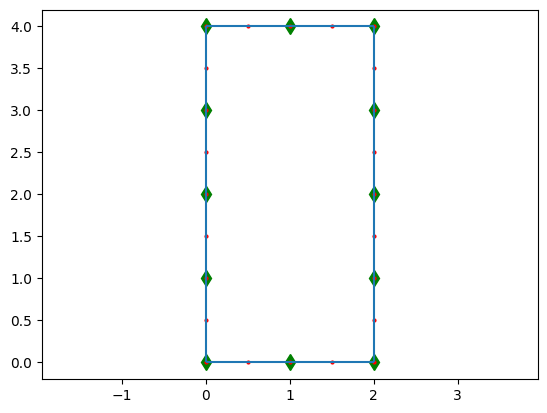

In [93]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
show_geometry(computed_data['coordinates'],xplot,yplot,computed_data['elements'],)

# Time function

In [105]:
time_function = np.array([[0., 1.],[1.E10, 1.]]) # Heaviside (step) function

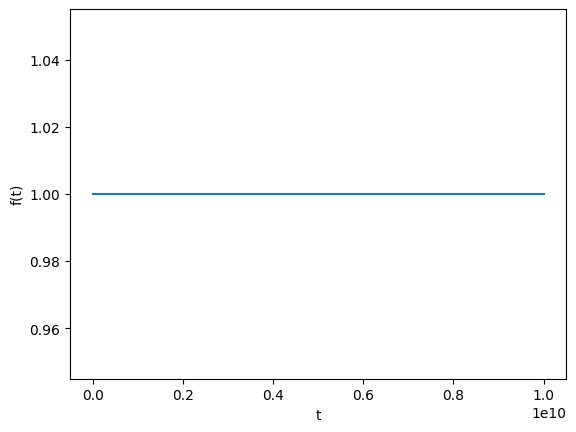

In [116]:
# plot time function
plt.plot(time_function[:,0],time_function[:,1])
plt.xlabel('t')
plt.ylabel('f(t)')
plt.show()

# Create input file (```str12.dat```)

In [111]:
import numpy as np

# Re-get the global `inp_data` dictionary to avoid shadowing
global_input_data = input_data()

inp_data_filename = 'str12.dat' # Output file name for quadplet

def create_input_file(filename, computed_data, input_params,time_function):
    """
    Creates an input file for the Fortran BEM program (quadplet) in the time domain
    based on computed mesh data and boundary conditions.
    """
    with open(filename, 'w') as f:
        # 1. Title Line
        f.write("INFINITE STRIP UNDER UNIFORM TRACTION\n\n")

        # Extract data from computed_data and input_params
        nodes = computed_data['coordinates']
        elements = computed_data['elements']
        num_elements = elements.shape[0]

        # 2. Basic Parameter Line
        ntfun = input_params.get('ntfunctions', 1)
        ipr = 1 # Printing interval
        nstep = 20 # Number of time steps
        tstep = float(input_params.get('tstep', 2.0E-4))

        # G = E / 2(1+v)
        G = float(input_params['E'] / (2 * (1 + input_params['nu'])))
        rho = float(input_params['rho'])
        nu = float(input_params['nu'])

        # Format float numbers to use uppercase E for Fortran compatibility
        f.write(f" {num_elements},{ntfun}   {ipr},{nstep},{tstep:.4E}   {G:.4E},{nu:.4E},{rho:.4E}\n\n")

        # 3. Boundary Nodes Coordinates Lines
        # Sequência geométrica desejada: no1 e no_meio de cada elemento
        node_coords_list = []
        for elem in elements:
            no1_idx = elem[0]
            no_meio_idx = elem[2]
            x1, y1 = nodes[no1_idx][0], nodes[no1_idx][1]
            xm, ym = nodes[no_meio_idx][0], nodes[no_meio_idx][1]
            node_coords_list.append(f"{float(x1):.4E} {float(y1):.4E}")
            node_coords_list.append(f"{float(xm):.4E} {float(ym):.4E}")

        f.write(" ")
        for i in range(0, len(node_coords_list), 8): # Wrap at 8 nodes per line
            f.write("  ".join(node_coords_list[i:i+8]) + "\n ")
        f.write("\n")

        # 4. Time Function lines
        #  scale 1.0
        scale = 1.
        n_time_points = time_function.shape[0]
        f.write(f" {n_time_points},{scale}\n ")

        # Write all points on a single line
        time_points_str = []
        for i in range(n_time_points):
            time_points_str.append(f"{time_function[i,0]},{time_function[i,1]}")
        f.write("  , ".join(time_points_str) + "\n\n")

        # 5. Boundary Conditions Lines
        segments = computed_data['segments']
        bc_info = computed_data['bc_info']

        for i in range(num_elements):
            segment_index = segments[i]
            # Find the boundary condition data corresponding to the current segment
            for bc_name, bc_data in bc_info.items():
                if bc_data['segment'] == segment_index:
                    tp_x = bc_data['type_x']
                    # Gracefully handle both lists and scalar floats from input_data
                    vl_x = float(bc_data['value_x'][0] if isinstance(bc_data['value_x'], list) else bc_data['value_x'])
                    tf_x = bc_data.get('tfun', 1)

                    tp_y = bc_data['type_y']
                    vl_y = float(bc_data['value_y'][0] if isinstance(bc_data['value_y'], list) else bc_data['value_y'])
                    tf_y = bc_data.get('tfun', 1)
                    break

            line_parts = []
            for n in range(3):
                line_parts.append(f"{tp_x},{vl_x:.4E},{tf_x} {tp_y},{vl_y:.4E},{tf_y}")
            f.write(f" {'  '.join(line_parts)}\n")

# Call the function to generate str12.dat
create_input_file(inp_data_filename, computed_data, global_input_data, time_function)


# List input file

In [112]:
!cat str12.dat

INFINITE STRIP UNDER UNIFORM TRACTION

 12,1   1,20,2.0000E-04   1.0000E+10,3.0000E-01,5.0000E+03

 0.0000E+00 0.0000E+00  5.0000E-01 0.0000E+00  1.0000E+00 0.0000E+00  1.5000E+00 0.0000E+00  2.0000E+00 0.0000E+00  2.0000E+00 5.0000E-01  2.0000E+00 1.0000E+00  2.0000E+00 1.5000E+00
 2.0000E+00 2.0000E+00  2.0000E+00 2.5000E+00  2.0000E+00 3.0000E+00  2.0000E+00 3.5000E+00  2.0000E+00 4.0000E+00  1.5000E+00 4.0000E+00  1.0000E+00 4.0000E+00  5.0000E-01 4.0000E+00
 0.0000E+00 4.0000E+00  0.0000E+00 3.5000E+00  0.0000E+00 3.0000E+00  0.0000E+00 2.5000E+00  0.0000E+00 2.0000E+00  0.0000E+00 1.5000E+00  0.0000E+00 1.0000E+00  0.0000E+00 5.0000E-01
 
 2,1.0
 0.0,1.0  , 10000000000.0,1.0

 1,0.0000E+00,1 0,0.0000E+00,1  1,0.0000E+00,1 0,0.0000E+00,1  1,0.0000E+00,1 0,0.0000E+00,1
 1,0.0000E+00,1 0,0.0000E+00,1  1,0.0000E+00,1 0,0.0000E+00,1  1,0.0000E+00,1 0,0.0000E+00,1
 0,0.0000E+00,1 1,0.0000E+00,1  0,0.0000E+00,1 1,0.0000E+00,1  0,0.0000E+00,1 1,0.0000E+00,1
 0,0.0000E+00,1 1,0.0000E+00,1

(1) Title line: The title of the problem.

(2)Basic Parameter line: Number of elements, number of time functions, printing interval, number of time steps, time interval size, shear modulus, Poisson's ratio, density.

(3)Boundary Node Coordinate lines: Contain node coordinates in counterclockwise order for external boundaries and clockwise order for internal ones.

(4)Time Function lines: As in all previous time domain codes, the following data should be read for each time function: one line with the number of points which define the function and the scale, and the pairs of values (time, function) which define the function in the following lines

(5)Boundary condition lines: This should read, for every element, for each node in the element, and for both X and Y direction: the boundary condition code (KODE = 0, the known value is the displacement, KODE - 1, the known value is the traction), the value of the boundary condition, and the number of the time function which defines its time variation.

# Compile the code ```quadplet.for```

In [113]:
!gfortran -std=legacy  -Wall  quadplet.for -o quadplet

quadplet.for:729:23:

  729 |       WRITE(IPR,400) X(2),Y(2),T(3,ISTEP),T(4,ISTEP),
      |                       1
quadplet.for:729:28:

  729 |       WRITE(IPR,400) X(2),Y(2),T(3,ISTEP),T(4,ISTEP),
      |                            1
quadplet.for:732:23:

  731 |       DO 70 I=2,NE
      |                                                                        2
  732 |       WRITE(IPR,400) X(2*I-1),Y(2*I-1),T(6*I-7,ISTEP),T(6*I-6,ISTEP),
      |                       1
quadplet.for:732:32:

  731 |       DO 70 I=2,NE
      |                                                                        2
  732 |       WRITE(IPR,400) X(2*I-1),Y(2*I-1),T(6*I-7,ISTEP),T(6*I-6,ISTEP),
      |                                1
quadplet.for:734:23:

  731 |       DO 70 I=2,NE
      |                                                                        2
......
  734 |    70 WRITE(IPR,400) X(2*I),  Y(2*I),  T(6*I-3,ISTEP),T(6*I-2,ISTEP),
      |                       1
quadplet.for:734:32:

  731

# Run ```quadpleh```

In [114]:
!./quadplet

 NAME OF THE INPUT  FILE (MAX. 12 CHAR.)    : NAME OF THE OUTPUT FILE (MAX. 12 CHAR.)    : NAME OF THE AUXILIARY FILE (MAX. 12 CHAR.) :           1
           2
           3
           4
           5
           6
           7
           8
           9
          10
          11
          12
          13
          14
          15
          16
          17
          18
          19
          20
Note: The following floating-point exceptions are signalling: IEEE_UNDERFLOW_FLAG IEEE_DENORMAL


# Numerical example

**Infinite strip under uniform step load**

In order to evaluate the relative advantage of different space and time interpolation functions, as well as to analyze the effect of the size of the time step, two elastodynamic problems solved by Domínguez and Gallego (1991) using the above formulation are studied. The first problem corresponds to an infinite strip under a uniform traction applied as a step function at time $t=0$ (Figure 4.8). The material properties are: Poisson's ratio $v=0.25$, shear modulus $\mu=$ $4 \times 10^4 \mathrm{~Pa} . \mathrm{P}$-wave velocity $\mathrm{c}_{\mathrm{r}}=346.41 \mathrm{~m} / \mathrm{s}$ and S-wave velocity $\mathrm{c}_{\mathrm{S}}=200 \mathrm{~m} / \mathrm{s}$.

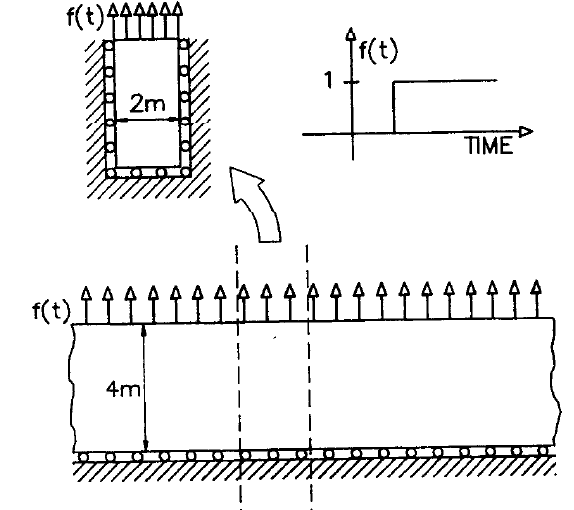

$ \mu = \frac{E}{2(1+\nu)}\Rightarrow E = 2\mu(1+\nu)$

# List output file

In [115]:
!head str12.out

 *******************************************************************************
INFINITE STRIP UNDER UNIFORM TRACTION                                           


  DATA

  NUMBER OF BOUNDARY ELEMENTS =  12
  NUMBER OF TIME FUNCTIONS    =   1
  INTERVAL OF PRINTING        =   1
  NUMBER OF TIME STEPS        =  20
